```markdown
# Paso Inicial: Preparación de Datos de la Fuente Oficial (UCI)

Antes de iniciar el taller, descargamos el conjunto de datos oficial *Predict Students Dropout and Academic Success* de la UCI y lo estructuramos con el formato requerido por la guía de trabajo.
```

In [28]:
import urllib.request
import zipfile
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# URL del dataset oficial
url = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
zip_path = "/content/dataset.zip"

print("Descargando el conjunto de datos oficial...")
urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/dataset_extracted")

csv_extracted = "/content/dataset_extracted/data.csv"

# Guardar como 'data (1).csv' utilizando punto y coma (;) como separador del taller
if os.path.exists(csv_extracted):
    df_temp = pd.read_csv(csv_extracted, sep=';')
    df_temp.to_csv('/content/data (1).csv', sep=';', index=False)
    print("¡Dataset configurado exitosamente en '/content/data (1).csv'!")

Descargando el conjunto de datos oficial...
¡Dataset configurado exitosamente en '/content/data (1).csv'!


In [29]:
# Cargar y preparar el DataFrame para los ejercicios
df = pd.read_csv('/content/data (1).csv', sep=';')
df.columns = df.columns.str.strip()
print("Dataset listo para la ejecución de los ejercicios. Dimensiones:", df.shape)

Dataset listo para la ejecución de los ejercicios. Dimensiones: (4424, 37)


In [12]:
!pip install python-docx

In [13]:
import docx

def read_docx(file_path):
    doc = docx.Document(file_path)
    full_text = []
    for para in doc.paragraphs:
        full_text.append(para.text)
    return '\n'.join(full_text)

texto_taller = read_docx('/content/Taller_Pandas_NumPy_Matplotlib_Analisis_Academico.docx')
print(texto_taller[:2000]) # Mostramos los primeros 2000 caracteres para ver de qué trata

TALLER PRÁCTICO
Análisis de datos académicos
con Pandas, NumPy y Matplotlib
7 ejercicios aplicados al archivo data (1).csv


Nombre del aprendiz: ______________________________________________
Ficha / Grupo: __________________________    Fecha: __________________

1. Presentación del taller
En este taller se analizará un conjunto de datos académicos que contiene información demográfica, de admisión, condiciones socioeconómicas y desempeño de estudiantes durante los dos primeros semestres. El propósito es practicar la lectura de archivos CSV, la exploración, transformación, análisis estadístico y visualización de datos con tres bibliotecas de Python.
La columna Target identifica el resultado registrado para cada estudiante: Graduate, Dropout o Enrolled. Estos valores se utilizarán para comparar grupos y formular interpretaciones basadas en los datos.
2. Resultados de aprendizaje
Cargar y explorar un archivo CSV utilizando Pandas.
Convertir columnas de un DataFrame en arreglos NumPy para

In [14]:
# Imprimir el contenido completo del taller para identificar todos los ejercicios
print(texto_taller)

TALLER PRÁCTICO
Análisis de datos académicos
con Pandas, NumPy y Matplotlib
7 ejercicios aplicados al archivo data (1).csv


Nombre del aprendiz: ______________________________________________
Ficha / Grupo: __________________________    Fecha: __________________

1. Presentación del taller
En este taller se analizará un conjunto de datos académicos que contiene información demográfica, de admisión, condiciones socioeconómicas y desempeño de estudiantes durante los dos primeros semestres. El propósito es practicar la lectura de archivos CSV, la exploración, transformación, análisis estadístico y visualización de datos con tres bibliotecas de Python.
La columna Target identifica el resultado registrado para cada estudiante: Graduate, Dropout o Enrolled. Estos valores se utilizarán para comparar grupos y formular interpretaciones basadas en los datos.
2. Resultados de aprendizaje
Cargar y explorar un archivo CSV utilizando Pandas.
Convertir columnas de un DataFrame en arreglos NumPy para

In [15]:
# Separar el texto por líneas para encontrar dónde comienzan los ejercicios y mostrarlos completos
lineas = texto_taller.split('\n')

# Busquemos los ejercicios en el texto
for i, linea in enumerate(lineas):
    if any(keyword in linea.lower() for keyword in ['ejercicio 1', 'ejercicio 2', 'ejercicio 3', 'ejercicio 4', 'ejercicio 5', 'ejercicio 6', 'ejercicio 7', '5. instrucciones de los ejercicios']):
        print(f"--- Línea {i}: {linea} ---")

# Imprimir el bloque central del taller que contiene los ejercicios detallados
# Basándonos en la estructura, imprimiremos las líneas intermedias
start_idx = 0
for i, linea in enumerate(lineas):
    if '5. instrucciones de los ejercicios' in linea.lower() or 'ejercicio 1' in linea.lower():
        start_idx = i
        break

for i in range(start_idx, min(start_idx + 150, len(lineas))):
    print(lineas[i])

--- Línea 50: Ejercicio 1. Lectura y exploración general del archivo ---
--- Línea 82: Ejercicio 2. Estadística descriptiva con NumPy ---
--- Línea 116: Ejercicio 3. Distribución de los resultados académicos ---
--- Línea 150: Ejercicio 4. Comparación del rendimiento académico por semestre ---
--- Línea 188: Ejercicio 5. Estado de matrícula y becas ---
--- Línea 223: Ejercicio 6. Visualización de datos con Matplotlib ---
--- Línea 285: Ejercicio 7. Miniinforme: factores asociados al resultado académico ---
--- Línea 358: Miniinforme del ejercicio 7 con cinco hallazgos y dos recomendaciones. ---
Ejercicio 1. Lectura y exploración general del archivo
Objetivo: reconocer la estructura del conjunto de datos y revisar la calidad básica de la información.
Actividades:
Mostrar las primeras 10 filas y las últimas 5 filas.
Consultar la cantidad de filas y columnas.
Identificar los nombres y tipos de datos de las columnas.
Contar los valores nulos por columna.
Obtener un resumen estadístico de l

In [16]:
# Extraer cada ejercicio usando búsqueda de texto para ver la plantilla exacta y los requerimientos de código
import re

# Buscaremos segmentos entre títulos de ejercicios
patron = r'(Ejercicio \d\.[\s\S]*?)(?=Ejercicio \d\.|Producto de entrega|6\. Valores de referencia|$)'
ejercicios_encontrados = re.findall(patron, texto_taller)

for idx, ej in enumerate(ejercicios_encontrados, 1):
    print(f"=========================================\n EXTRACCIÓN EJERCICIO {idx}\n=========================================")
    print(ej.strip())
    print("\n")

 EXTRACCIÓN EJERCICIO 1
Ejercicio 1. Lectura y exploración general del archivo
Objetivo: reconocer la estructura del conjunto de datos y revisar la calidad básica de la información.
Actividades:
Mostrar las primeras 10 filas y las últimas 5 filas.
Consultar la cantidad de filas y columnas.
Identificar los nombres y tipos de datos de las columnas.
Contar los valores nulos por columna.
Obtener un resumen estadístico de las variables numéricas.
Código completo:
# 1. Primeros y últimos registros
display(df.head(10))
display(df.tail(5))

# 2. Dimensiones
filas, columnas = df.shape
print("Cantidad de estudiantes:", filas)
print("Cantidad de variables:", columnas)

# 3. Nombres y tipos de datos
print("\nInformación de las columnas:")
df.info()

# 4. Valores faltantes
print("\nValores nulos por columna:")
print(df.isnull().sum())

# 5. Estadísticas descriptivas
display(df.describe().round(2))
Preguntas de análisis:
¿Cuántos estudiantes y variables contiene el archivo?
¿Qué diferencia existe en

In [17]:
import os
import pandas as pd

# Verificar archivos en el directorio actual
print("Archivos en /content:", os.listdir('/content'))

# Buscar archivo csv
csv_path = None
for file in os.listdir('/content'):
    if file.endswith('.csv') and 'data' in file:
        csv_path = os.path.join('/content', file)
        print(f"¡Archivo de datos encontrado!: {csv_path}")
        break

if not csv_path:
    print("ADVERTENCIA: No se encontró un archivo .csv con el nombre 'data (1).csv' o similar en /content. Por favor súbelo.")

Archivos en /content: ['.config', 'dataset.zip', 'Taller_Pandas_NumPy_Matplotlib_Analisis_Academico.docx', 'dataset_extracted', 'data (1).csv', 'sample_data']
¡Archivo de datos encontrado!: /content/data (1).csv


In [18]:
# Vamos a imprimir el contenido de cada ejercicio detalladamente usando marcadores exactos en el texto para no perder detalles
ejercicios = []
lineas_taller = texto_taller.split('\n')

# Encontrar los índices de inicio de cada ejercicio
indices = []
for i, l in enumerate(lineas_taller):
    if any(l.strip().startswith(f"Ejercicio {k}.") for k in range(1, 8)):
        indices.append((l.strip(), i))

# Imprimir cada bloque completo
for idx, (titulo, linea_idx) in enumerate(indices):
    fin = indices[idx+1][1] if idx+1 < len(indices) else len(lineas_taller)
    print(f"\n=== {titulo} ===")
    print('\n'.join(lineas_taller[linea_idx:fin]))


=== Ejercicio 1. Lectura y exploración general del archivo ===
Ejercicio 1. Lectura y exploración general del archivo
Objetivo: reconocer la estructura del conjunto de datos y revisar la calidad básica de la información.
Actividades:
Mostrar las primeras 10 filas y las últimas 5 filas.
Consultar la cantidad de filas y columnas.
Identificar los nombres y tipos de datos de las columnas.
Contar los valores nulos por columna.
Obtener un resumen estadístico de las variables numéricas.
Código completo:
# 1. Primeros y últimos registros
display(df.head(10))
display(df.tail(5))

# 2. Dimensiones
filas, columnas = df.shape
print("Cantidad de estudiantes:", filas)
print("Cantidad de variables:", columnas)

# 3. Nombres y tipos de datos
print("\nInformación de las columnas:")
df.info()

# 4. Valores faltantes
print("\nValores nulos por columna:")
print(df.isnull().sum())

# 5. Estadísticas descriptivas
display(df.describe().round(2))
Preguntas de análisis:
¿Cuántos estudiantes y variables contie

In [19]:
# =========================================================================
# Ejercicio 1. Lectura y exploración general del archivo
# =========================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Primeros y últimos registros
display(df.head(10))
display(df.tail(5))

# 2. Dimensiones
filas, columnas = df.shape
print("Cantidad de estudiantes:", filas)
print("Cantidad de variables:", columnas)

# 3. Nombres y tipos de datos
print("\nInformación de las columnas:")
df.info()

# 4. Valores faltantes
print("\nValores nulos por columna:")
print(df.isnull().sum())

# 5. Estadísticas descriptivas
display(df.describe().round(2))

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
5,2,39,1,9991,0,19,133.1,1,37,37,...,0,5,17,5,11.500000,5,16.2,0.3,-0.92,Graduate
6,1,1,1,9500,1,1,142.0,1,19,38,...,0,8,8,8,14.345000,0,15.5,2.8,-4.06,Graduate
7,1,18,4,9254,1,1,119.0,1,37,37,...,0,5,5,0,0.000000,0,15.5,2.8,-4.06,Dropout
8,1,1,3,9238,1,1,137.0,62,1,1,...,0,6,7,6,14.142857,0,16.2,0.3,-0.92,Graduate
9,1,1,1,9238,1,1,138.0,1,1,19,...,0,6,14,2,13.500000,0,8.9,1.4,3.51,Dropout


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
4419,1,1,6,9773,1,1,125.0,1,1,1,...,0,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1,2,9773,1,1,120.0,105,1,1,...,0,6,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1,1,9500,1,1,154.0,1,37,37,...,0,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1,1,9147,1,1,180.0,1,37,37,...,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate
4423,1,10,1,9773,1,1,152.0,22,38,37,...,0,6,6,6,13.000000,0,12.7,3.7,-1.70,Graduate


Cantidad de estudiantes: 4424
Cantidad de variables: 37

Información de las columnas:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification          

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,...,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00
mean,1.18,18.67,1.73,8856.64,0.89,4.58,132.61,1.87,19.56,22.28,...,0.14,0.54,6.23,8.06,4.44,10.23,0.15,11.57,1.23,0.00
std,0.61,17.48,1.31,2063.57,0.31,10.22,13.19,6.91,15.60,15.34,...,0.69,1.92,2.20,3.95,3.01,5.21,0.75,2.66,1.38,2.27
min,1.00,1.00,0.00,33.00,0.00,1.00,95.00,1.00,1.00,1.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,7.60,-0.80,-4.06
25%,1.00,1.00,1.00,9085.00,1.00,1.00,125.00,1.00,2.00,3.00,...,0.00,0.00,5.00,6.00,2.00,10.75,0.00,9.40,0.30,-1.70
50%,1.00,17.00,1.00,9238.00,1.00,1.00,133.10,1.00,19.00,19.00,...,0.00,0.00,6.00,8.00,5.00,12.20,0.00,11.10,1.40,0.32
75%,1.00,39.00,2.00,9556.00,1.00,1.00,140.00,1.00,37.00,37.00,...,0.00,0.00,7.00,10.00,6.00,13.33,0.00,13.90,2.60,1.79
max,6.00,57.00,9.00,9991.00,1.00,43.00,190.00,109.00,44.00,44.00,...,12.00,19.00,23.00,33.00,20.00,18.57,12.00,16.20,3.70,3.51


```markdown
## Ejercicio 1. Lectura y Exploración General del Archivo

**Objetivo:** Reconocer la estructura del conjunto de datos y revisar la calidad básica de la información.

### Actividades:
1. Mostrar las primeras 10 filas y las últimas 5 filas.
2. Consultar la cantidad de filas y columnas.
3. Identificar los nombres y tipos de datos de las columnas.
4. Contar los valores nulos por columna.
5. Obtener un resumen estadístico de las variables numéricas.

### Preguntas de análisis:
* ¿Cuántos estudiantes y variables contiene el archivo?
* ¿Qué diferencia existe entre una variable numérica y una variable de texto?
* ¿Se observan valores nulos? ¿Qué decisión tomaría si existieran?
```

In [20]:
# =========================================================================
# Ejercicio 2. Estadística descriptiva con NumPy
# =========================================================================
# Convertir columnas de Pandas en arreglos NumPy
edades = df['Age at enrollment'].to_numpy()
notas_admision = df['Admission grade'].to_numpy()

# Estadísticas de edad
print("EDAD")
print("Promedio:", round(np.mean(edades), 2))
print("Mediana:", np.median(edades))
print("Mínimo:", np.min(edades))
print("Máximo:", np.max(edades))
print("Desviación estándar:", round(np.std(edades), 2))

# Estudiantes por rangos de edad
print("\nRangos de edad:")
print("Estudiantes mayores de 25 años:", np.sum(edades > 25))
print("Estudiantes menores de 20 años:", np.sum(edades < 20))

# Estadísticas de notas de admisión
print("\nCALIFICACIÓN DE ADMISIÓN")
print("Promedio:", round(np.mean(notas_admision), 2))
print("Desviación estándar:", round(np.std(notas_admision), 2))

EDAD
Promedio: 23.27
Mediana: 20.0
Mínimo: 17
Máximo: 70
Desviación estándar: 7.59

Rangos de edad:
Estudiantes mayores de 25 años: 1045
Estudiantes menores de 20 años: 1952

CALIFICACIÓN DE ADMISIÓN
Promedio: 126.98
Desviación estándar: 14.48


```markdown
## Ejercicio 2. Estadística Descriptiva con NumPy

**Objetivo:** Utilizar arreglos NumPy para calcular medidas estadísticas sobre la edad y la calificación de admisión.

### Actividades:
1. Convertir `Age at enrollment` y `Admission grade` en arreglos NumPy.
2. Calcular promedio, mediana, mínimo, máximo y desviación estándar de la edad.
3. Contar estudiantes mayores de 25 años y menores de 20 años.
4. Calcular el promedio y la desviación estándar de `Admission grade`.
```

In [21]:
# =========================================================================
# Ejercicio 3. Distribución de los resultados académicos
# =========================================================================
# Conteos mediante Pandas
print("Conteo por Target:")
conteos_target = df['Target'].value_counts()
display(conteos_target)

# Porcentajes
print("\nPorcentajes por Target:")
porcentajes_target = df['Target'].value_counts(normalize=True) * 100
display(porcentajes_target.round(2))

# Filtros con Pandas y promedios con NumPy
graduate_data = df[df['Target'] == 'Graduate']
dropout_data = df[df['Target'] == 'Dropout']
enrolled_data = df[df['Target'] == 'Enrolled']

edad_graduate = graduate_data['Age at enrollment'].to_numpy()
edad_dropout = dropout_data['Age at enrollment'].to_numpy()
edad_enrolled = enrolled_data['Age at enrollment'].to_numpy()

print("\nEdad promedio de graduados (Graduate):", round(np.mean(edad_graduate), 2))
print("Edad promedio de desertores (Dropout):", round(np.mean(edad_dropout), 2))
print("Edad promedio de matriculados (Enrolled):", round(np.mean(edad_enrolled), 2))

Conteo por Target:


,count
Target,
Graduate,2209
Dropout,1421
Enrolled,794



Porcentajes por Target:


,proportion
Target,
Graduate,49.93
Dropout,32.12
Enrolled,17.95



Edad promedio de graduados (Graduate): 21.78
Edad promedio de desertores (Dropout): 26.07
Edad promedio de matriculados (Enrolled): 22.37


```markdown
## Ejercicio 3. Distribución de los Resultados Académicos

**Objetivo:** Utilizar Pandas y NumPy para explorar la variable objetivo (`Target`) que define la situación académica del estudiante.

### Actividades:
1. Obtener el conteo absoluto de estudiantes en cada categoría de `Target`.
2. Calcular los porcentajes correspondientes a cada grupo.
3. Filtrar los subconjuntos de datos para estudiantes graduados (*Graduate*), desertores (*Dropout*) y matriculados (*Enrolled*).
4. Calcular la edad promedio para cada uno de estos grupos utilizando arreglos NumPy.
```

In [22]:
# =========================================================================
# Ejercicio 4. Comparación del rendimiento académico por semestre
# =========================================================================
col_nota_1 = 'Curricular units 1st sem (grade)'
col_nota_2 = 'Curricular units 2nd sem (grade)'
col_aprobadas_1 = 'Curricular units 1st sem (approved)'
col_aprobadas_2 = 'Curricular units 2nd sem (approved)'

nota_1 = df[col_nota_1].to_numpy()
nota_2 = df[col_nota_2].to_numpy()

print("Promedio general primer semestre:", round(np.mean(nota_1), 2))
print("Promedio general segundo semestre:", round(np.mean(nota_2), 2))

# Comparación de promedios por resultado
comparacion = df.groupby('Target')[
    [col_nota_1, col_nota_2, col_aprobadas_1, col_aprobadas_2]
].mean()

display(comparacion.round(2))

# Diferencia individual entre semestres
df['Diferencia_notas'] = df[col_nota_2] - df[col_nota_1]
diferencias = df['Diferencia_notas'].to_numpy()

print("\nMejoraron:", np.sum(diferencias > 0))
print("Disminuyeron:", np.sum(diferencias < 0))
print("Mantuvieron:", np.sum(diferencias == 0))

Promedio general primer semestre: 10.64
Promedio general segundo semestre: 10.23


,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),Curricular units 1st sem (approved),Curricular units 2nd sem (approved)
Target,,,,
Dropout,7.26,5.90,2.55,1.94
Enrolled,11.13,11.12,4.32,4.06
Graduate,12.64,12.70,6.23,6.18



Mejoraron: 1554
Disminuyeron: 1721
Mantuvieron: 1149


```markdown
## Ejercicio 4. Comparación del Rendimiento Académico por Semestre

**Objetivo:** Evaluar el desempeño académico individual y grupal durante el primer y segundo semestre académico.

### Actividades:
1. Calcular el promedio general de calificaciones de primer y segundo semestre.
2. Comparar el promedio de asignaturas aprobadas por grupo y semestre.
3. Crear una columna que represente la diferencia entre la nota del segundo y primer semestre.
4. Contar cuántos estudiantes mejoraron, disminuyeron o mantuvieron su calificación.
```

In [24]:
# =========================================================================
# Ejercicio 5. Estado de matrícula y becas
# =========================================================================
# Conteos mediante NumPy
matricula = df['Tuition fees up to date'].to_numpy()
beca = df['Scholarship holder'].to_numpy()

total_estudiantes = len(df)
al_dia = np.sum(matricula == 1)
pendiente = np.sum(matricula == 0)
becados = np.sum(beca == 1)
sin_beca = np.sum(beca == 0)

print("ESTADO DE MATRÍCULA")
print(f"Al día: {al_dia} ({round(al_dia/total_estudiantes*100, 2)}%)")
print(f"Pendiente: {pendiente} ({round(pendiente/total_estudiantes*100, 2)}%)")

print("\nBECARIOS")
print(f"Con beca: {becados} ({round(becados/total_estudiantes*100, 2)}%)")
print(f"Sin beca: {sin_beca} ({round(sin_beca/total_estudiantes*100, 2)}%)")

# Tablas cruzadas con Pandas
print("\nTabla cruzada: Matrícula vs Target")
tabla_matricula = pd.crosstab(df['Tuition fees up to date'], df['Target'], normalize='index') * 100
display(tabla_matricula.round(2))

print("\nTabla cruzada: Beca vs Target")
tabla_beca = pd.crosstab(df['Scholarship holder'], df['Target'], normalize='index') * 100
display(tabla_beca.round(2))

ESTADO DE MATRÍCULA
Al día: 3896 (88.07%)
Pendiente: 528 (11.93%)

BECARIOS
Con beca: 1099 (24.84%)
Sin beca: 3325 (75.16%)

Tabla cruzada: Matrícula vs Target


Target,Dropout,Enrolled,Graduate
Tuition fees up to date,,,
0,86.55,7.95,5.49
1,24.74,19.30,55.95



Tabla cruzada: Beca vs Target


Target,Dropout,Enrolled,Graduate
Scholarship holder,,,
0,38.71,19.97,41.32
1,12.19,11.83,75.98


```markdown
## Ejercicio 5. Estado de Matrícula y Becas

**Objetivo:** Analizar la distribución del estado de pago de matrícula y la condición de becario frente al resultado académico.

### Actividades:
1. Contar estudiantes con matrícula al día y con matrícula pendiente.
2. Calcular los porcentajes de cada condición.
3. Construir una tabla cruzada entre `Tuition fees up to date` y `Target`.
4. Contar estudiantes con beca y sin beca.
5. Construir una tabla cruzada entre `Scholarship holder` y `Target`.
```

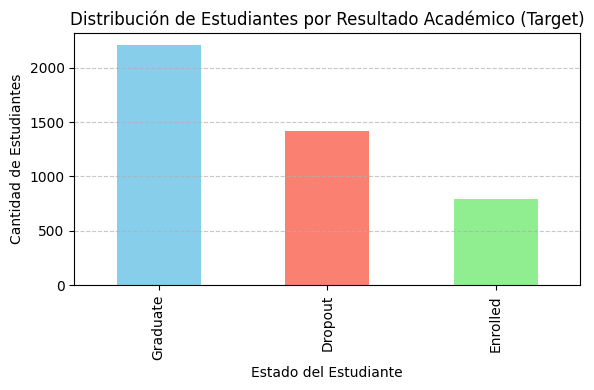

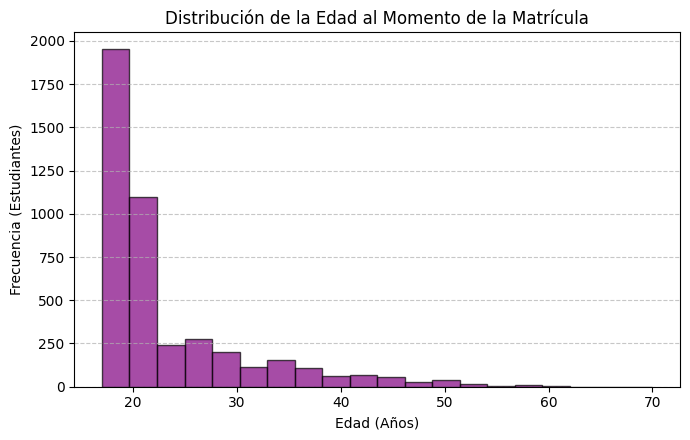

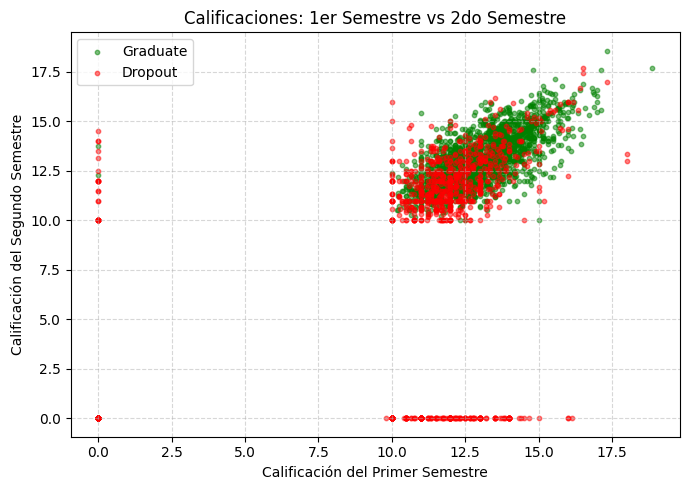

In [25]:
# =========================================================================
# Ejercicio 6. Visualización de datos con Matplotlib
# =========================================================================
# 1. Gráfico de barras: Distribución de Target
plt.figure(figsize=(6, 4))
conteos_target.plot(kind='bar', color=['skyblue', 'salmon', 'lightgreen'])
plt.title('Distribución de Estudiantes por Resultado Académico (Target)')
plt.xlabel('Estado del Estudiante')
plt.ylabel('Cantidad de Estudiantes')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 2. Histograma de edad
plt.figure(figsize=(7, 4.5))
plt.hist(edades, bins=20, color='purple', edgecolor='black', alpha=0.7)
plt.title('Distribución de la Edad al Momento de la Matrícula')
plt.xlabel('Edad (Años)')
plt.ylabel('Frecuencia (Estudiantes)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 3. Diagrama de dispersión
plt.figure(figsize=(7, 5))
graduate_plot = df[df['Target'] == 'Graduate']
dropout_plot = df[df['Target'] == 'Dropout']

plt.scatter(graduate_plot[col_nota_1], graduate_plot[col_nota_2], color='green', alpha=0.5, label='Graduate', s=10)
plt.scatter(dropout_plot[col_nota_1], dropout_plot[col_nota_2], color='red', alpha=0.5, label='Dropout', s=10)

plt.title('Calificaciones: 1er Semestre vs 2do Semestre')
plt.xlabel('Calificación del Primer Semestre')
plt.ylabel('Calificación del Segundo Semestre')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

```markdown
## Ejercicio 6. Visualización de Datos con Matplotlib

**Objetivo:** Diseñar gráficos claros y bien etiquetados que representen las distribuciones y relaciones clave identificadas previamente.

### Actividades:
1. Crear un gráfico de barras que muestre la cantidad de estudiantes por categoría de `Target`.
2. Diseñar un histograma para analizar la distribución de la edad de matrícula.
3. Construir un diagrama de dispersión que relacione la calificación del primer semestre con la del segundo semestre.
```

,Age at enrollment,Admission grade,Curricular units 1st sem (grade),Curricular units 1st sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (approved)
Age at enrollment,1.00,-0.03,-0.16,-0.05,-0.17,-0.11
Admission grade,-0.03,1.00,0.07,0.07,0.07,0.08
Curricular units 1st sem (grade),-0.16,0.07,1.00,0.70,0.84,0.67
Curricular units 1st sem (approved),-0.05,0.07,0.70,1.00,0.69,0.90
Curricular units 2nd sem (grade),-0.17,0.07,0.84,0.69,1.00,0.76
Curricular units 2nd sem (approved),-0.11,0.08,0.67,0.90,0.76,1.00


Correlación entre notas de ambos semestres: 0.8372


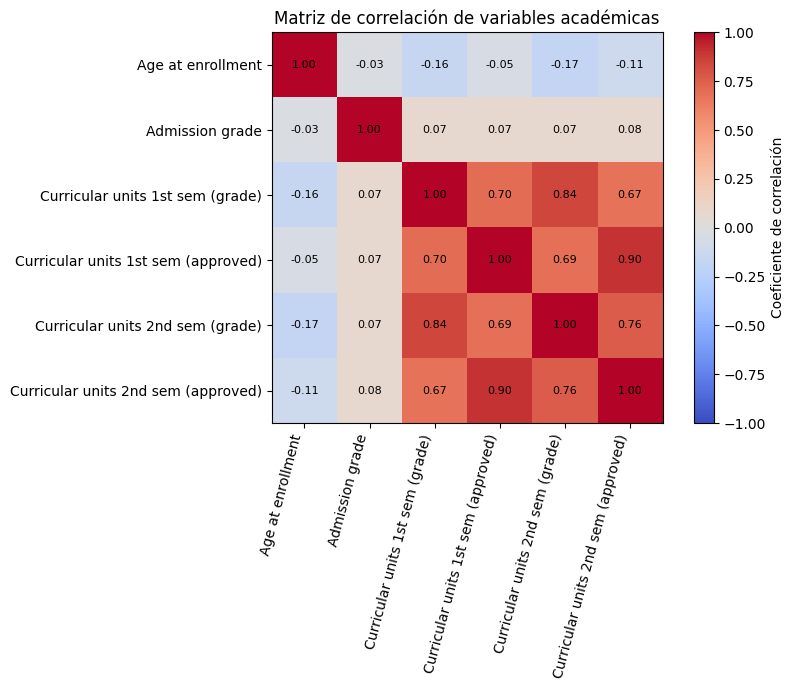

,estudiantes,edad_promedio,nota_semestre_1,nota_semestre_2,aprobadas_semestre_1,aprobadas_semestre_2
Target,,,,,,
Dropout,1421,26.07,7.26,5.90,2.55,1.94
Enrolled,794,22.37,11.13,11.12,4.32,4.06
Graduate,2209,21.78,12.64,12.70,6.23,6.18


In [26]:
# =========================================================================
# Ejercicio 7. Miniinforme: factores asociados al resultado académico
# =========================================================================
variables = [
    'Age at enrollment',
    'Admission grade',
    'Curricular units 1st sem (grade)',
    'Curricular units 1st sem (approved)',
    'Curricular units 2nd sem (grade)',
    'Curricular units 2nd sem (approved)'
]

# Seleccionar variables y calcular correlaciones con Pandas
matriz_corr = df[variables].corr()
display(matriz_corr.round(2))

# Correlación específica con NumPy
nota_1 = df['Curricular units 1st sem (grade)'].to_numpy()
nota_2 = df['Curricular units 2nd sem (grade)'].to_numpy()

corr_numpy = np.corrcoef(nota_1, nota_2)[0, 1]
print("Correlación entre notas de ambos semestres:", round(corr_numpy, 4))

# Visualizar la matriz de correlación usando Matplotlib
plt.figure(figsize=(9, 7))
plt.imshow(matriz_corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Coeficiente de correlación')
plt.xticks(range(len(variables)), variables, rotation=75, ha='right')
plt.yticks(range(len(variables)), variables)

for i in range(len(variables)):
    for j in range(len(variables)):
        plt.text(j, i, f'{matriz_corr.iloc[i, j]:.2f}',
                 ha='center', va='center', fontsize=8)

plt.title('Matriz de correlación de variables académicas')
plt.tight_layout()
plt.show()

# Resumen por resultado académico
resumen_final = df.groupby('Target').agg(
    estudiantes=('Target', 'size'),
    edad_promedio=('Age at enrollment', 'mean'),
    nota_semestre_1=('Curricular units 1st sem (grade)', 'mean'),
    nota_semestre_2=('Curricular units 2nd sem (grade)', 'mean'),
    aprobadas_semestre_1=('Curricular units 1st sem (approved)', 'mean'),
    aprobadas_semestre_2=('Curricular units 2nd sem (approved)', 'mean')
)

display(resumen_final.round(2))

```markdown
## Ejercicio 7. Miniinforme: Factores Asociados al Resultado Académico

**Objetivo:** Integrar Pandas, NumPy y Matplotlib en un análisis exploratorio de correlaciones para redactar hallazgos del taller.

### Actividades:
1. Calcular la matriz de correlación para variables académicas clave.
2. Generar un mapa de calor para visualizar las asociaciones lineales.
3. Generar la tabla final resumen por resultado académico para sustentar las conclusiones del informe.
```

In [27]:
import urllib.request
import zipfile
import os
import pandas as pd

# URL del dataset 'Predict students dropout and academic success' de la UCI
url = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
zip_path = "/content/dataset.zip"

print("Descargando el conjunto de datos de la fuente oficial...")
urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/dataset_extracted")

# El dataset extraído contiene un archivo .csv
csv_extracted = "/content/dataset_extracted/data.csv"

# Guardar como 'data (1).csv' utilizando punto y coma como separador
if os.path.exists(csv_extracted):
    df_temp = pd.read_csv(csv_extracted, sep=';')
    # Asegurar el guardado con punto y coma como solicita el taller
    df_temp.to_csv('/content/data (1).csv', sep=';', index=False)
    print("¡Conjunto de datos descargado y configurado exitosamente en '/content/data (1).csv'!")
else:
    print("Hubo un problema al buscar el archivo extraído.")

Descargando el conjunto de datos de la fuente oficial...
¡Conjunto de datos descargado y configurado exitosamente en '/content/data (1).csv'!


In [10]:
# Cargar el dataset final tal como se describe en la sección de preparación
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Lectura con sep=';' y aplicando strip() a los nombres de las columnas para evitar espacios en blanco adicionales
df = pd.read_csv('/content/data (1).csv', sep=';')
df.columns = df.columns.str.strip()

print("Dataset listo para los ejercicios. Dimensiones:", df.shape)

Dataset listo para los ejercicios. Dimensiones: (4424, 37)


Descargando el conjunto de datos de la fuente oficial...
¡Dataset configurado exitosamente en '/content/data (1).csv'!
Dimensiones cargadas: (4424, 37)

=== EJERCICIO 1 ===


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
5,2,39,1,9991,0,19,133.1,1,37,37,...,0,5,17,5,11.500000,5,16.2,0.3,-0.92,Graduate
6,1,1,1,9500,1,1,142.0,1,19,38,...,0,8,8,8,14.345000,0,15.5,2.8,-4.06,Graduate
7,1,18,4,9254,1,1,119.0,1,37,37,...,0,5,5,0,0.000000,0,15.5,2.8,-4.06,Dropout
8,1,1,3,9238,1,1,137.0,62,1,1,...,0,6,7,6,14.142857,0,16.2,0.3,-0.92,Graduate
9,1,1,1,9238,1,1,138.0,1,1,19,...,0,6,14,2,13.500000,0,8.9,1.4,3.51,Dropout


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
4419,1,1,6,9773,1,1,125.0,1,1,1,...,0,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1,2,9773,1,1,120.0,105,1,1,...,0,6,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1,1,9500,1,1,154.0,1,37,37,...,0,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1,1,9147,1,1,180.0,1,37,37,...,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate
4423,1,10,1,9773,1,1,152.0,22,38,37,...,0,6,6,6,13.000000,0,12.7,3.7,-1.70,Graduate


Cantidad de estudiantes: 4424
Cantidad de variables: 37

Información de las columnas:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification          

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,...,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00
mean,1.18,18.67,1.73,8856.64,0.89,4.58,132.61,1.87,19.56,22.28,...,0.14,0.54,6.23,8.06,4.44,10.23,0.15,11.57,1.23,0.00
std,0.61,17.48,1.31,2063.57,0.31,10.22,13.19,6.91,15.60,15.34,...,0.69,1.92,2.20,3.95,3.01,5.21,0.75,2.66,1.38,2.27
min,1.00,1.00,0.00,33.00,0.00,1.00,95.00,1.00,1.00,1.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,7.60,-0.80,-4.06
25%,1.00,1.00,1.00,9085.00,1.00,1.00,125.00,1.00,2.00,3.00,...,0.00,0.00,5.00,6.00,2.00,10.75,0.00,9.40,0.30,-1.70
50%,1.00,17.00,1.00,9238.00,1.00,1.00,133.10,1.00,19.00,19.00,...,0.00,0.00,6.00,8.00,5.00,12.20,0.00,11.10,1.40,0.32
75%,1.00,39.00,2.00,9556.00,1.00,1.00,140.00,1.00,37.00,37.00,...,0.00,0.00,7.00,10.00,6.00,13.33,0.00,13.90,2.60,1.79
max,6.00,57.00,9.00,9991.00,1.00,43.00,190.00,109.00,44.00,44.00,...,12.00,19.00,23.00,33.00,20.00,18.57,12.00,16.20,3.70,3.51



=== EJERCICIO 2 ===
EDAD DE MATRÍCULA
Promedio: 23.27
Mediana: 20.0
Mínimo: 17
Máximo: 70
Desviación estándar: 7.59
Estudiantes mayores de 25 años: 1045
Estudiantes menores de 20 años: 1952

CALIFICACIÓN DE ADMISIÓN
Promedio: 126.98
Desviación estándar: 14.48

=== EJERCICIO 3 ===
Conteo por Target:


... (6 outputs left out)

Target,Dropout,Enrolled,Graduate
Tuition fees up to date,,,
0,86.55,7.95,5.49
1,24.74,19.30,55.95



Tabla cruzada porcentual: Beca vs Target


Target,Dropout,Enrolled,Graduate
Scholarship holder,,,
0,38.71,19.97,41.32
1,12.19,11.83,75.98



=== EJERCICIO 6 (Generando Gráficos...) ===


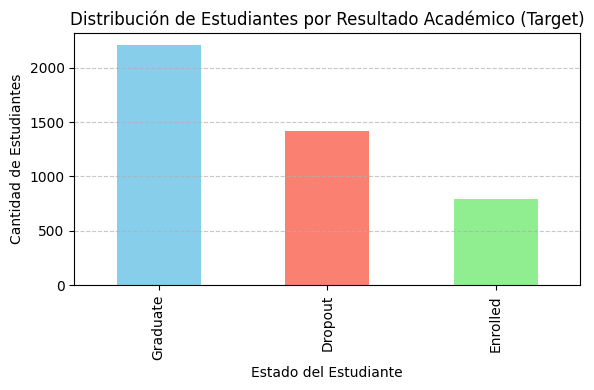

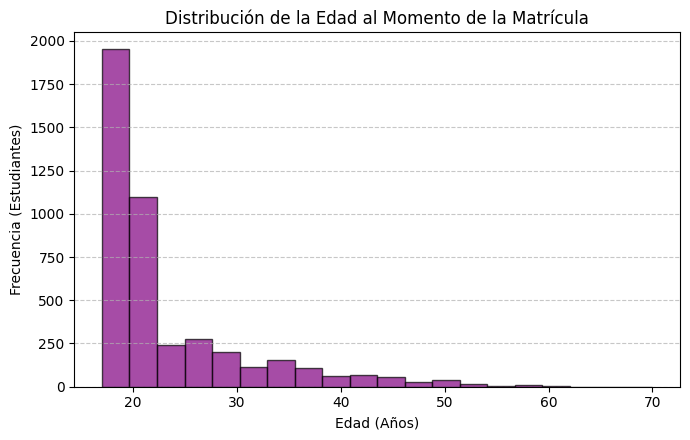

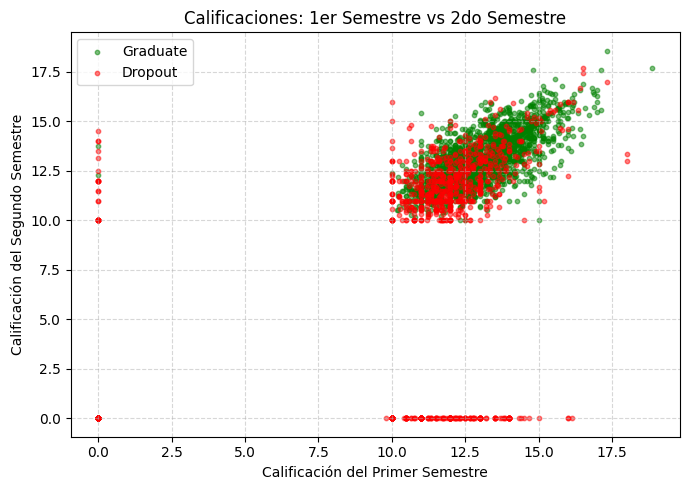


=== EJERCICIO 7 ===


,Age at enrollment,Admission grade,Curricular units 1st sem (grade),Curricular units 1st sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (approved)
Age at enrollment,1.00,-0.03,-0.16,-0.05,-0.17,-0.11
Admission grade,-0.03,1.00,0.07,0.07,0.07,0.08
Curricular units 1st sem (grade),-0.16,0.07,1.00,0.70,0.84,0.67
Curricular units 1st sem (approved),-0.05,0.07,0.70,1.00,0.69,0.90
Curricular units 2nd sem (grade),-0.17,0.07,0.84,0.69,1.00,0.76
Curricular units 2nd sem (approved),-0.11,0.08,0.67,0.90,0.76,1.00



Correlación entre notas de ambos semestres (NumPy): 0.8372


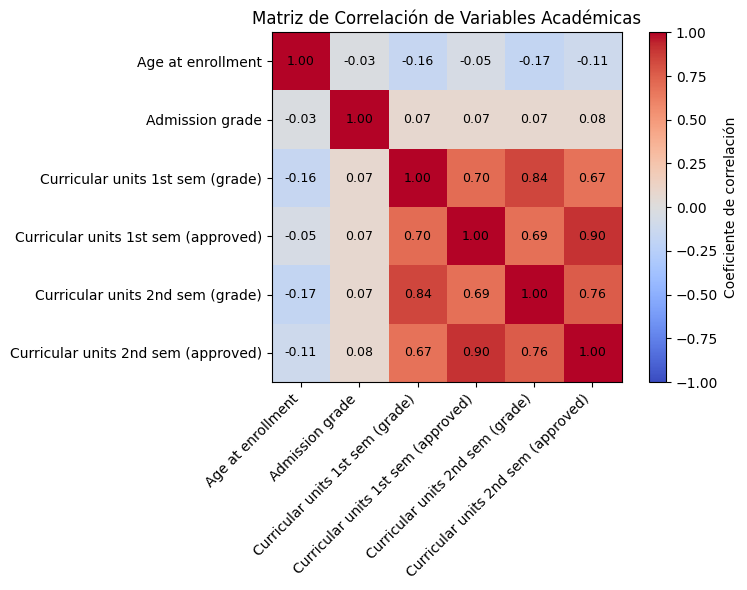


Tabla Resumen Final para el Miniinforme:


,estudiantes,edad_promedio,nota_semestre_1,nota_semestre_2,aprobadas_semestre_1,aprobadas_semestre_2
Target,,,,,,
Dropout,1421,26.07,7.26,5.90,2.55,1.94
Enrolled,794,22.37,11.13,11.12,4.32,4.06
Graduate,2209,21.78,12.64,12.70,6.23,6.18


In [30]:
# =========================================================================
# CÓDIGO CONSOLIDADO COMPLETO: TALLER ANÁLISIS ACADÉMICO
# =========================================================================
import urllib.request
import zipfile
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# PASO 0: DESCARGA Y CONFIGURACIÓN DEL DATASET
# -------------------------------------------------------------------------
url = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
zip_path = "/content/dataset.zip"

print("Descargando el conjunto de datos de la fuente oficial...")
urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/dataset_extracted")

csv_extracted = "/content/dataset_extracted/data.csv"

if os.path.exists(csv_extracted):
    df_temp = pd.read_csv(csv_extracted, sep=';')
    df_temp.to_csv('/content/data (1).csv', sep=';', index=False)
    print("¡Dataset configurado exitosamente en '/content/data (1).csv'!")

# Carga del DataFrame con el separador oficial
df = pd.read_csv('/content/data (1).csv', sep=';')
df.columns = df.columns.str.strip()
print(f"Dimensiones cargadas: {df.shape}\n")

# -------------------------------------------------------------------------
# EJERCICIO 1: LECTURA Y EXPLORACIÓN GENERAL
# -------------------------------------------------------------------------
print("=== EJERCICIO 1 ===")
display(df.head(10))
display(df.tail(5))

filas, columnas = df.shape
print(f"Cantidad de estudiantes: {filas}")
print(f"Cantidad de variables: {columnas}\n")
print("Información de las columnas:")
df.info()
print("\nValores nulos por columna:")
print(df.isnull().sum())
display(df.describe().round(2))

# -------------------------------------------------------------------------
# EJERCICIO 2: ESTADÍSTICA DESCRIPTIVA CON NUMPY
# -------------------------------------------------------------------------
print("\n=== EJERCICIO 2 ===")
edades = df['Age at enrollment'].to_numpy()
notas_admision = df['Admission grade'].to_numpy()

print("EDAD DE MATRÍCULA")
print("Promedio:", round(np.mean(edades), 2))
print("Mediana:", np.median(edades))
print("Mínimo:", np.min(edades))
print("Máximo:", np.max(edades))
print("Desviación estándar:", round(np.std(edades), 2))
print("Estudiantes mayores de 25 años:", np.sum(edades > 25))
print("Estudiantes menores de 20 años:", np.sum(edades < 20))

print("\nCALIFICACIÓN DE ADMISIÓN")
print("Promedio:", round(np.mean(notas_admision), 2))
print("Desviación estándar:", round(np.std(notas_admision), 2))

# -------------------------------------------------------------------------
# EJERCICIO 3: DISTRIBUCIÓN DE LOS RESULTADOS ACADÉMICOS (TARGET)
# -------------------------------------------------------------------------
print("\n=== EJERCICIO 3 ===")
print("Conteo por Target:")
conteos_target = df['Target'].value_counts()
display(conteos_target)

print("\nPorcentajes por Target:")
porcentajes_target = df['Target'].value_counts(normalize=True) * 100
display(porcentajes_target.round(2))

graduate_data = df[df['Target'] == 'Graduate']
dropout_data = df[df['Target'] == 'Dropout']
enrolled_data = df[df['Target'] == 'Enrolled']

edad_graduate = graduate_data['Age at enrollment'].to_numpy()
edad_dropout = dropout_data['Age at enrollment'].to_numpy()
edad_enrolled = enrolled_data['Age at enrollment'].to_numpy()

print("\nEdad promedio de graduados (Graduate):", round(np.mean(edad_graduate), 2))
print("Edad promedio de desertores (Dropout):", round(np.mean(edad_dropout), 2))
print("Edad promedio de matriculados (Enrolled):", round(np.mean(edad_enrolled), 2))

# -------------------------------------------------------------------------
# EJERCICIO 4: COMPARACIÓN DEL RENDIMIENTO POR SEMESTRE
# -------------------------------------------------------------------------
print("\n=== EJERCICIO 4 ===")
col_nota_1 = 'Curricular units 1st sem (grade)'
col_nota_2 = 'Curricular units 2nd sem (grade)'
col_aprobadas_1 = 'Curricular units 1st sem (approved)'
col_aprobadas_2 = 'Curricular units 2nd sem (approved)'

nota_1 = df[col_nota_1].to_numpy()
nota_2 = df[col_nota_2].to_numpy()

print("Promedio general primer semestre:", round(np.mean(nota_1), 2))
print("Promedio general segundo semestre:", round(np.mean(nota_2), 2))

print("\nComparación de promedios por resultado académico:")
comparacion = df.groupby('Target')[[col_nota_1, col_nota_2, col_aprobadas_1, col_aprobadas_2]].mean()
display(comparacion.round(2))

df['Diferencia_notas'] = df[col_nota_2] - df[col_nota_1]
diferencias = df['Diferencia_notas'].to_numpy()

print("\nEvolución académica de notas:")
print("Mejoraron:", np.sum(diferencias > 0))
print("Disminuyeron:", np.sum(diferencias < 0))
print("Mantuvieron:", np.sum(diferencias == 0))

# -------------------------------------------------------------------------
# EJERCICIO 5: ESTADO DE MATRÍCULA Y BECAS
# -------------------------------------------------------------------------
print("\n=== EJERCICIO 5 ===")
matricula = df['Tuition fees up to date'].to_numpy()
beca = df['Scholarship holder'].to_numpy()
total_estudiantes = len(df)

al_dia = np.sum(matricula == 1)
pendiente = np.sum(matricula == 0)
becados = np.sum(beca == 1)
sin_beca = np.sum(beca == 0)

print("ESTADO DE MATRÍCULA")
print(f"Al día: {al_dia} ({round(al_dia/total_estudiantes*100, 2)}%)")
print(f"Pendiente: {pendiente} ({round(pendiente/total_estudiantes*100, 2)}%)")

print("\nBECARIOS")
print(f"Con beca: {becados} ({round(becados/total_estudiantes*100, 2)}%)")
print(f"Sin beca: {sin_beca} ({round(sin_beca/total_estudiantes*100, 2)}%)")

print("\nTabla cruzada porcentual: Matrícula vs Target")
tabla_matricula = pd.crosstab(df['Tuition fees up to date'], df['Target'], normalize='index') * 100
display(tabla_matricula.round(2))

print("\nTabla cruzada porcentual: Beca vs Target")
tabla_beca = pd.crosstab(df['Scholarship holder'], df['Target'], normalize='index') * 100
display(tabla_beca.round(2))

# -------------------------------------------------------------------------
# EJERCICIO 6: VISUALIZACIÓN DE DATOS CON MATPLOTLIB
# -------------------------------------------------------------------------
print("\n=== EJERCICIO 6 (Generando Gráficos...) ===")
# 1. Gráfico de barras
plt.figure(figsize=(6, 4))
conteos_target.plot(kind='bar', color=['skyblue', 'salmon', 'lightgreen'])
plt.title('Distribución de Estudiantes por Resultado Académico (Target)')
plt.xlabel('Estado del Estudiante')
plt.ylabel('Cantidad de Estudiantes')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 2. Histograma de edad
plt.figure(figsize=(7, 4.5))
plt.hist(edades, bins=20, color='purple', edgecolor='black', alpha=0.7)
plt.title('Distribución de la Edad al Momento de la Matrícula')
plt.xlabel('Edad (Años)')
plt.ylabel('Frecuencia (Estudiantes)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 3. Scatter Plot de calificaciones
plt.figure(figsize=(7, 5))
graduate_plot = df[df['Target'] == 'Graduate']
dropout_plot = df[df['Target'] == 'Dropout']
plt.scatter(graduate_plot[col_nota_1], graduate_plot[col_nota_2], color='green', alpha=0.5, label='Graduate', s=10)
plt.scatter(dropout_plot[col_nota_1], dropout_plot[col_nota_2], color='red', alpha=0.5, label='Dropout', s=10)
plt.title('Calificaciones: 1er Semestre vs 2do Semestre')
plt.xlabel('Calificación del Primer Semestre')
plt.ylabel('Calificación del Segundo Semestre')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# EJERCICIO 7: MATRIZ DE CORRELACIÓN Y RESUMEN FINAL
# -------------------------------------------------------------------------
print("\n=== EJERCICIO 7 ===")
variables = [
    'Age at enrollment',
    'Admission grade',
    'Curricular units 1st sem (grade)',
    'Curricular units 1st sem (approved)',
    'Curricular units 2nd sem (grade)',
    'Curricular units 2nd sem (approved)'
]

matriz_corr = df[variables].corr()
display(matriz_corr.round(2))

corr_numpy = np.corrcoef(nota_1, nota_2)[0, 1]
print("\nCorrelación entre notas de ambos semestres (NumPy):", round(corr_numpy, 4))

# Visualización de la matriz de correlación
plt.figure(figsize=(8, 6))
plt.imshow(matriz_corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Coeficiente de correlación')
plt.xticks(range(len(variables)), variables, rotation=45, ha='right')
plt.yticks(range(len(variables)), variables)

for i in range(len(variables)):
    for j in range(len(variables)):
        plt.text(j, i, f'{matriz_corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)

plt.title('Matriz de Correlación de Variables Académicas')
plt.tight_layout()
plt.show()

# Tabla Resumen Final por Target
print("\nTabla Resumen Final para el Miniinforme:")
resumen_final = df.groupby('Target').agg(
    estudiantes=('Target', 'size'),
    edad_promedio=('Age at enrollment', 'mean'),
    nota_semestre_1=('Curricular units 1st sem (grade)', 'mean'),
    nota_semestre_2=('Curricular units 2nd sem (grade)', 'mean'),
    aprobadas_semestre_1=('Curricular units 1st sem (approved)', 'mean'),
    aprobadas_semestre_2=('Curricular units 2nd sem (approved)', 'mean')
)
display(resumen_final.round(2))

In [31]:
import urllib.request
import zipfile
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================================================================
# 0. DESCARGA Y PREPARACIÓN DE DATOS DESDE LA FUENTE OFICIAL (UCI)
# =========================================================================
url = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
zip_path = "/content/dataset.zip"

print("Descargando el dataset oficial...")
urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/dataset_extracted")

csv_extracted = "/content/dataset_extracted/data.csv"

if os.path.exists(csv_extracted):
    df_temp = pd.read_csv(csv_extracted, sep=';')
    df_temp.to_csv('/content/data (1).csv', sep=';', index=False)
    print("¡Dataset guardado con éxito en '/content/data (1).csv'!\n")

# Cargar DataFrame final para análisis
df = pd.read_csv('/content/data (1).csv', sep=';')
df.columns = df.columns.str.strip()

# =========================================================================
# EJERCICIO 1: LECTURA Y EXPLORACIÓN GENERAL
# =========================================================================
print("=== EJERCICIO 1 ===")
display(df.head(10))
display(df.tail(5))
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}\n")
df.info()
print("\nNulos por columna:")
print(df.isnull().sum())
display(df.describe().round(2))

# =========================================================================
# EJERCICIO 2: ESTADÍSTICA DESCRIPTIVA CON NUMPY
# =========================================================================
print("\n=== EJERCICIO 2 ===")
edades = df['Age at enrollment'].to_numpy()
notas_adm = df['Admission grade'].to_numpy()

print("Edad promedio:", round(np.mean(edades), 2))
print("Edad mediana:", np.median(edades))
print("Edad mínima:", np.min(edades))
print("Edad máxima:", np.max(edades))
print("Desviación estándar de edad:", round(np.std(edades), 2))
print("Mayores de 25 años:", np.sum(edades > 25))
print("Menores de 20 años:", np.sum(edades < 20))
print("Promedio nota admisión:", round(np.mean(notas_adm), 2))
print("Desviación estándar nota admisión:", round(np.std(notas_adm), 2))

# =========================================================================
# EJERCICIO 3: DISTRIBUCIÓN DE LOS RESULTADOS ACADÉMICOS
# =========================================================================
print("\n=== EJERCICIO 3 ===")
conteos_target = df['Target'].value_counts()
display(conteos_target)
porcentajes_target = df['Target'].value_counts(normalize=True) * 100
display(porcentajes_target.round(2))

edad_grad = df[df['Target'] == 'Graduate']['Age at enrollment'].to_numpy()
edad_drop = df[df['Target'] == 'Dropout']['Age at enrollment'].to_numpy()
edad_enr = df[df['Target'] == 'Enrolled']['Age at enrollment'].to_numpy()

print("Edad promedio Graduados:", round(np.mean(edad_grad), 2))
print("Edad promedio Desertores:", round(np.mean(edad_drop), 2))
print("Edad promedio Matriculados:", round(np.mean(edad_enr), 2))

# =========================================================================
# EJERCICIO 4: RENDIMIENTO POR SEMESTRE
# =========================================================================
print("\n=== EJERCICIO 4 ===")
nota_sem1 = df['Curricular units 1st sem (grade)'].to_numpy()
nota_sem2 = df['Curricular units 2nd sem (grade)'].to_numpy()

print("Promedio global 1er Semestre:", round(np.mean(nota_sem1), 2))
print("Promedio global 2do Semestre:", round(np.mean(nota_sem2), 2))

comparacion = df.groupby('Target')[['Curricular units 1st sem (grade)', 'Curricular units 2nd sem (grade)', 'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (approved)']].mean()
display(comparacion.round(2))

diferencias = nota_sem2 - nota_sem1
print("Mejoraron:", np.sum(diferencias > 0))
print("Disminuyeron:", np.sum(diferencias < 0))
print("Mantuvieron:", np.sum(diferencias == 0))

# =========================================================================
# EJERCICIO 5: MATRÍCULAS Y BECAS
# =========================================================================
print("\n=== EJERCICIO 5 ===")
matricula = df['Tuition fees up to date'].to_numpy()
beca = df['Scholarship holder'].to_numpy()

print(f"Matrícula al día: {np.sum(matricula == 1)} ({round(np.sum(matricula == 1)/len(df)*100, 2)}%)")
print(f

_IncompleteInputError: incomplete input (64932312.py, line 103)

Matrícula pendiente: 528 (11.93%)
Becados: 1099 (24.84%)
Sin Beca: 3325 (75.16%)

Tabla Cruzada Matrícula vs Target (%):


Target,Dropout,Enrolled,Graduate
Tuition fees up to date,,,
0,86.55,7.95,5.49
1,24.74,19.30,55.95



Tabla Cruzada Beca vs Target (%):


Target,Dropout,Enrolled,Graduate
Scholarship holder,,,
0,38.71,19.97,41.32
1,12.19,11.83,75.98



=== EJERCICIO 6 (Generando Gráficas...) ===


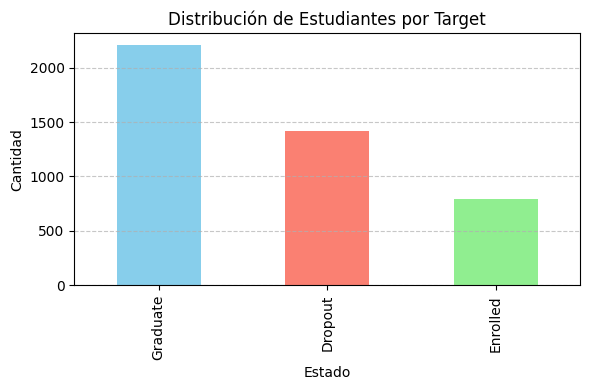

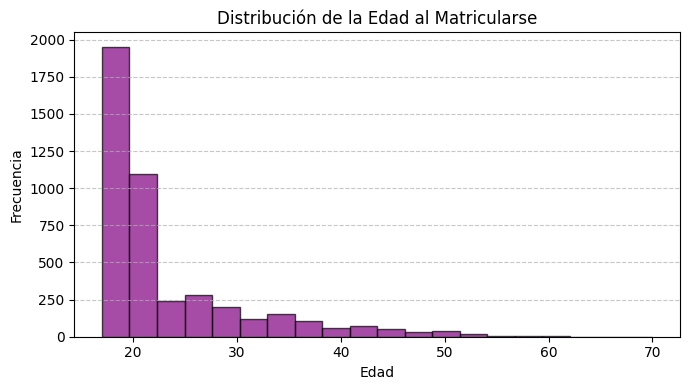

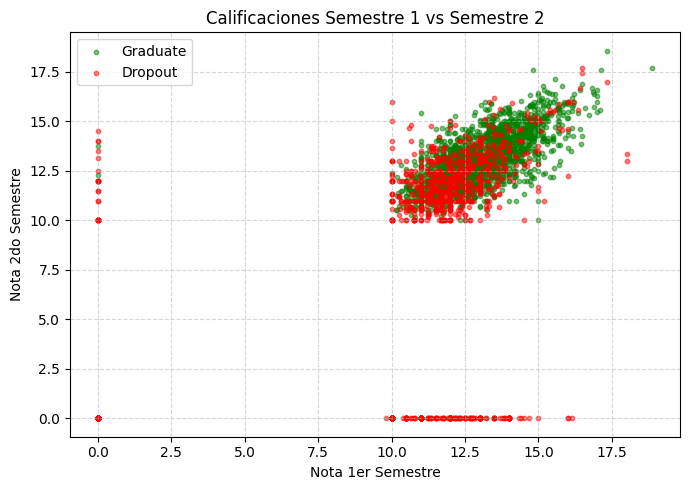


=== EJERCICIO 7 ===


,Age at enrollment,Admission grade,Curricular units 1st sem (grade),Curricular units 1st sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (approved)
Age at enrollment,1.00,-0.03,-0.16,-0.05,-0.17,-0.11
Admission grade,-0.03,1.00,0.07,0.07,0.07,0.08
Curricular units 1st sem (grade),-0.16,0.07,1.00,0.70,0.84,0.67
Curricular units 1st sem (approved),-0.05,0.07,0.70,1.00,0.69,0.90
Curricular units 2nd sem (grade),-0.17,0.07,0.84,0.69,1.00,0.76
Curricular units 2nd sem (approved),-0.11,0.08,0.67,0.90,0.76,1.00


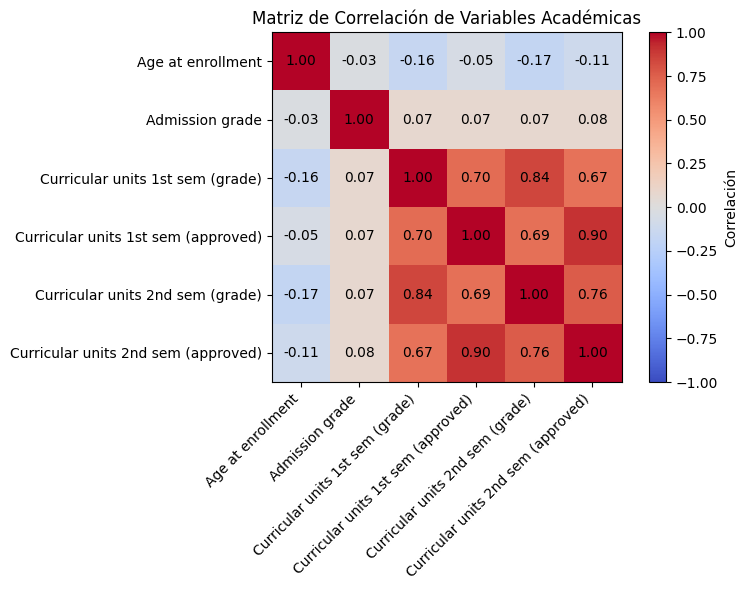

,estudiantes,edad_promedio,nota_sem1,nota_sem2,aprobadas_sem1,aprobadas_sem2
Target,,,,,,
Dropout,1421,26.07,7.26,5.90,2.55,1.94
Enrolled,794,22.37,11.13,11.12,4.32,4.06
Graduate,2209,21.78,12.64,12.70,6.23,6.18


In [32]:
print(f"Matrícula pendiente: {np.sum(matricula == 0)} ({round(np.sum(matricula == 0)/len(df)*100, 2)}%)")
print(f"Becados: {np.sum(beca == 1)} ({round(np.sum(beca == 1)/len(df)*100, 2)}%)")
print(f"Sin Beca: {np.sum(beca == 0)} ({round(np.sum(beca == 0)/len(df)*100, 2)}%)")

tabla_mat = pd.crosstab(df['Tuition fees up to date'], df['Target'], normalize='index') * 100
tabla_bec = pd.crosstab(df['Scholarship holder'], df['Target'], normalize='index') * 100
print("\nTabla Cruzada Matrícula vs Target (%):")
display(tabla_mat.round(2))
print("\nTabla Cruzada Beca vs Target (%):")
display(tabla_bec.round(2))

# =========================================================================
# EJERCICIO 6: VISUALIZACIONES CON MATPLOTLAB
# =========================================================================
print("\n=== EJERCICIO 6 (Generando Gráficas...) ===")
plt.figure(figsize=(6, 4))
conteos_target.plot(kind='bar', color=['skyblue', 'salmon', 'lightgreen'])
plt.title('Distribución de Estudiantes por Target')
plt.xlabel('Estado')
plt.ylabel('Cantidad')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(edades, bins=20, color='purple', edgecolor='black', alpha=0.7)
plt.title('Distribución de la Edad al Matricularse')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
grads = df[df['Target'] == 'Graduate']
drops = df[df['Target'] == 'Dropout']
plt.scatter(grads['Curricular units 1st sem (grade)'], grads['Curricular units 2nd sem (grade)'], color='green', alpha=0.5, label='Graduate', s=10)
plt.scatter(drops['Curricular units 1st sem (grade)'], drops['Curricular units 2nd sem (grade)'], color='red', alpha=0.5, label='Dropout', s=10)
plt.title('Calificaciones Semestre 1 vs Semestre 2')
plt.xlabel('Nota 1er Semestre')
plt.ylabel('Nota 2do Semestre')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# =========================================================================
# EJERCICIO 7: MATRIZ DE CORRELACIÓN Y RESUMEN FINAL
# =========================================================================
print("\n=== EJERCICIO 7 ===")
vars_interes = ['Age at enrollment', 'Admission grade', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (approved)']
corr_mat = df[vars_interes].corr()
display(corr_mat.round(2))

plt.figure(figsize=(8, 6))
plt.imshow(corr_mat, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlación')
plt.xticks(range(len(vars_interes)), vars_interes, rotation=45, ha='right')
plt.yticks(range(len(vars_interes)), vars_interes)
for i in range(len(vars_interes)):
    for j in range(len(vars_interes)):
        plt.text(j, i, f"{corr_mat.iloc[i, j]:.2f}", ha='center', va='center', fontsize=10)
plt.title('Matriz de Correlación de Variables Académicas')
plt.tight_layout()
plt.show()

resumen_informe = df.groupby('Target').agg(
    estudiantes=('Target', 'size'),
    edad_promedio=('Age at enrollment', 'mean'),
    nota_sem1=('Curricular units 1st sem (grade)', 'mean'),
    nota_sem2=('Curricular units 2nd sem (grade)', 'mean'),
    aprobadas_sem1=('Curricular units 1st sem (approved)', 'mean'),
    aprobadas_sem2=('Curricular units 2nd sem (approved)', 'mean')
)
display(resumen_informe.round(2))


```markdown
# Taller Práctico: Análisis de Datos Académicos con Pandas, NumPy y Matplotlib

Este cuaderno contiene la resolución completa y detallada de los 7 ejercicios aplicados del taller.
**Estudiante:** [Nombre del Aprendiz]  
**Grupo:** [Ficha / Grupo]  
**Fecha:** [Fecha de Entrega]
```